In [11]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

In [2]:
df = pd.read_csv("../dataset/creditcard.csv")
df = df.drop_duplicates()

X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape, X_test.shape)

(226980, 30) (56746, 30)


In [4]:
#Logistic Regression (Baseline Model) without SMOTE
from sklearn.pipeline import make_pipeline
lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=3000, random_state=42)
)

lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.85      0.58      0.69        95

    accuracy                           1.00     56746
   macro avg       0.92      0.79      0.84     56746
weighted avg       1.00      1.00      1.00     56746



In [5]:
#Logistic Regression (Baseline Model) with SMOTE
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

lr_smote = Pipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('model', LogisticRegression(max_iter=3000, random_state=42))
])

lr_smote.fit(X_train, y_train)
y_pred_smote = lr_smote.predict(X_test)
print(classification_report(y_test, y_pred_smote))

              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56651
           1       0.05      0.87      0.10        95

    accuracy                           0.97     56746
   macro avg       0.53      0.92      0.54     56746
weighted avg       1.00      0.97      0.99     56746



In [6]:
print(confusion_matrix(y_test, y_pred_smote))

[[55169  1482]
 [   12    83]]


Observations – Logistic Regression
Without SMOTE:
* Achieved 85% precision and 58% recall for fraud detection.
* The model is conservative when identifying fraudulent transactions.
* It misses approximately 42% of actual fraudulent transactions.

With SMOTE:
* Recall improved significantly from 58% to 87%.
* Precision dropped to just 5%, indicating many false positives.
* SMOTE improved fraud detection but introduced too many false alarms.

Conclusion: SMOTE alone isn’t sufficient. We need to explore better balancing techniques and classification models.

In [7]:
#2. Decision Tree – Without SMOTE
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.72      0.71      0.71        95

    accuracy                           1.00     56746
   macro avg       0.86      0.85      0.86     56746
weighted avg       1.00      1.00      1.00     56746



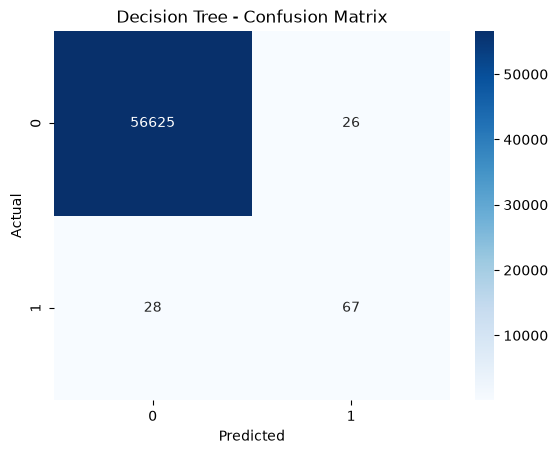

In [12]:
cm = confusion_matrix(y_test, y_pred_dt)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Decision Tree - Confusion Matrix')
plt.show()

Observations – Decision Tree (Without SMOTE)
* Achieved 72% precision and 71% recall for fraudulent transactions.
* Improved fraud detection compared to Logistic Regression without SMOTE.
* Correctly identified 67 out of 95 fraudulent transactions.
* Produced only 26 false positives, indicating relatively few false alarms.

Conclusion: Decision Tree performed slightly better than Logistic Regression based on F1-score. However, it still missed 28 fraudulent transactions.

In [13]:
#Decision Tree with SMOTE
dt_smote = Pipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('model', DecisionTreeClassifier(random_state=42))
])

dt_smote.fit(X_train, y_train)
y_pred_dt_smote = dt_smote.predict(X_test)
print(classification_report(y_test, y_pred_dt_smote))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.35      0.64      0.46        95

    accuracy                           1.00     56746
   macro avg       0.68      0.82      0.73     56746
weighted avg       1.00      1.00      1.00     56746



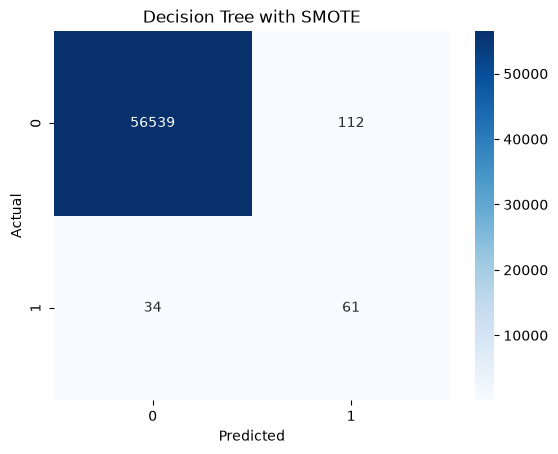

In [14]:
cm = confusion_matrix(y_test, y_pred_dt_smote)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Decision Tree with SMOTE')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Observations – Decision Tree with SMOTE

* Achieved 64% recall and 35% precision for fraudulent transactions.
* Performance decreased compared to Decision Tree without SMOTE.
* Generated 112 false positives and missed 34 fraudulent transactions.
* SMOTE did not improve the Decision Tree’s ability to generalise to unseen transactions.

Conclusion: Decision Tree without SMOTE performed better, achieving an F1-score of 0.71 compared to 0.46 with SMOTE. This demonstrates that oversampling does not necessarily improve every ML algorithm

In [ ]:
#Random Forest Classifier without SMOTE
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.97      0.73      0.83        95

    accuracy                           1.00     56746
   macro avg       0.99      0.86      0.92     56746
weighted avg       1.00      1.00      1.00     56746



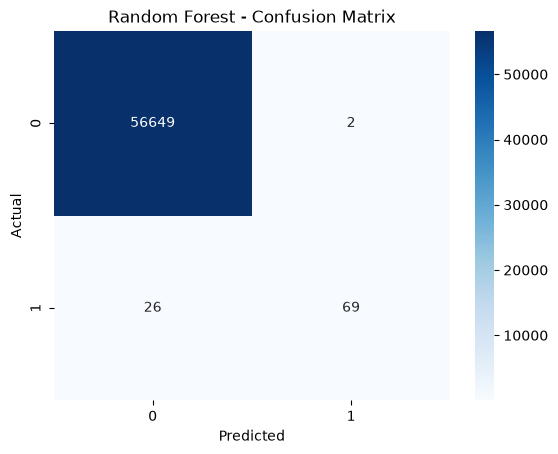

In [16]:
cm = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title('Random Forest - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Observations – Random Forest (Without SMOTE)

* Random Forest outperformed Logistic Regression and Decision Tree in terms of F1-score.
* Ensemble learning improved predictive performance compared to a single Decision Tree.
* Achieved excellent precision with very few false positives.
* However, it still missed 26 fraudulent transactions.

Conclusion: Random Forest without SMOTE is our current best model, achieving an F1-score of 0.83. Its high precision makes it particularly promising for fraud detection.

In [17]:
#Random Forest with SMOTE
rf_smote = Pipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('model', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

rf_smote.fit(X_train, y_train)
y_pred_rf_smote = rf_smote.predict(X_test)
print(classification_report(y_test, y_pred_rf_smote))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.91      0.77      0.83        95

    accuracy                           1.00     56746
   macro avg       0.96      0.88      0.92     56746
weighted avg       1.00      1.00      1.00     56746



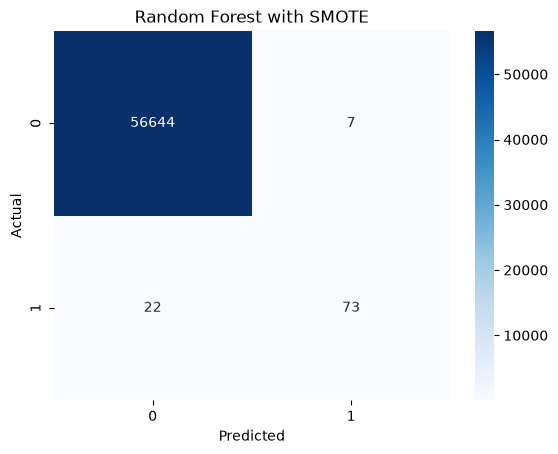

In [18]:
cm = confusion_matrix(y_test, y_pred_rf_smote)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Random Forest with SMOTE')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Observations – Random Forest with SMOTE

* Achieved 91% precision and 77% recall.
* Recall improved from 73% to 77% compared to Random Forest without SMOTE.
* Correctly detected 73 out of 95 fraudulent transactions.
* False positives increased slightly from 2 to 7.
* F1-score remained approximately 0.83.

Conclusion: SMOTE improved fraud detection recall while maintaining strong precision. Both Random Forest approaches perform well, with SMOTE detecting more fraudulent transactions at the cost of a few additional false positives.

In [19]:
#XGBoost – Without SMOTE
from xgboost import XGBClassifier
xgb = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)
xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_test)
print(classification_report(y_test, y_pred_xgb))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.96      0.72      0.82        95

    accuracy                           1.00     56746
   macro avg       0.98      0.86      0.91     56746
weighted avg       1.00      1.00      1.00     56746



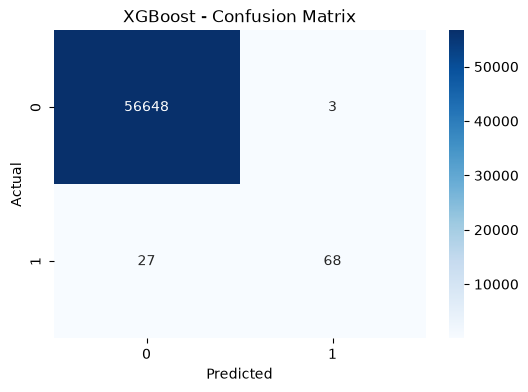

In [22]:
cm = confusion_matrix(y_test, y_pred_xgb)

plt.figure(figsize=(6, 4))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('XGBoost - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Observations – XGBoost (Without SMOTE)

* Achieved 96% precision and 72% recall for fraudulent transactions.
* Demonstrated excellent precision with only 3 false positives.
* Correctly identified 68 out of 95 fraudulent transactions.
* Performance was very close to Random Forest, although its F1-score was slightly lower.

Conclusion: XGBoost demonstrated strong classification performance. However, Random Forest without SMOTE currently performs slightly better, achieving an F1-score of 0.83 compared to XGBoost’s 0.82.

In [23]:
#XGBoost with SMOTE
xgb_smote = Pipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('model', XGBClassifier(
        n_estimators=100,
        max_depth=5,
        learning_rate=0.1,
        random_state=42,
        eval_metric='logloss',
        n_jobs=-1
    ))
])

xgb_smote.fit(X_train, y_train)
y_pred_xgb_smote = xgb_smote.predict(X_test)
print(classification_report(y_test, y_pred_xgb_smote))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.24      0.82      0.37        95

    accuracy                           1.00     56746
   macro avg       0.62      0.91      0.68     56746
weighted avg       1.00      1.00      1.00     56746



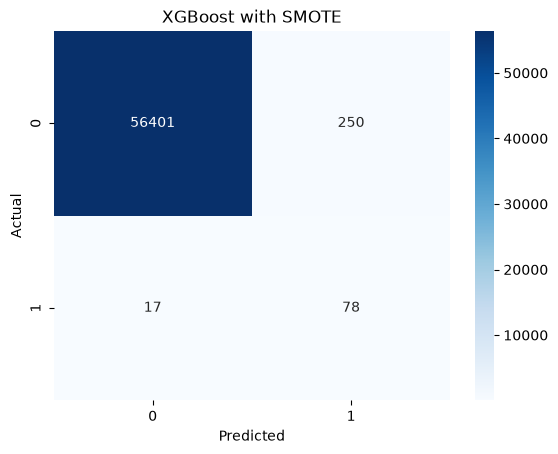

In [24]:
cm = confusion_matrix(y_test, y_pred_xgb_smote)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('XGBoost with SMOTE')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Observations – XGBoost with SMOTE

* Achieved 82% recall, improving from 72% without SMOTE.
* Precision dropped significantly from 96% to 24%.
* Correctly identified 78 fraudulent transactions.
* Generated 250 false positives, indicating a substantial increase in false alarms.

Conclusion: SMOTE improved XGBoost’s ability to detect fraudulent transactions but significantly increased false positives. Its F1-score decreased from 0.82 to 0.37, making the model less balanced overall.

IMPORTANT FINDINGS:

1. Random Forest is currently our strongest model, achieving an F1-score of 0.83.
2. SMOTE increases recall in some algorithms but can significantly reduce precision.
3. No single algorithm benefits equally from SMOTE.

5. Hyperparameter Tuning – Random Forest.

In [25]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import randint

In [26]:
param_dist = {
    'n_estimators': randint(100, 400),
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': randint(2, 10),
    'min_samples_leaf': randint(1, 5),
    'max_features': ['sqrt', 'log2']
}

In [27]:
rf_tuning = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

In [28]:
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

random_search = RandomizedSearchCV(
    estimator=rf_tuning,
    param_distributions=param_dist,
    n_iter=15,
    scoring='f1',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [29]:
random_search.fit(X_train, y_train)

Fitting 3 folds for each of 15 candidates, totalling 45 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [None, 10, ...], 'max_features': ['sqrt', 'log2'], 'min_samples_leaf': <scipy.stats....t 0x168d81d30>, 'min_samples_split': <scipy.stats....t 0x168e1c620>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",15
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score incho

In [30]:
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(random_search.best_score_)

Best Parameters:
{'max_depth': 10, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 113}

Best Cross-Validation F1 Score:
0.8412467577954903


In [31]:
best_rf = random_search.best_estimator_

y_pred_tuned = best_rf.predict(X_test)

print(classification_report(y_test, y_pred_tuned))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.97      0.72      0.82        95

    accuracy                           1.00     56746
   macro avg       0.99      0.86      0.91     56746
weighted avg       1.00      1.00      1.00     56746



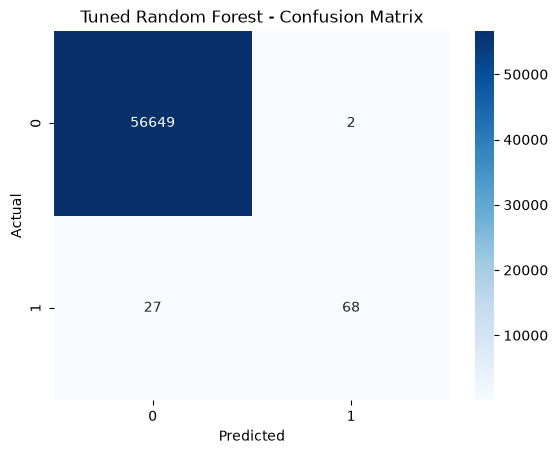

In [32]:
cm = confusion_matrix(y_test, y_pred_tuned)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title('Tuned Random Forest - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Observations – Tuned Random Forest

* Achieved 97% precision and 72% recall.
* Maintained excellent precision with only 2 false positives.
* Performance was almost identical to the original Random Forest.
* Hyperparameter tuning did not produce a significant improvement in test performance.

Conclusion: Although RandomizedSearchCV identified a configuration with a cross-validation F1-score of 0.8412, its test F1-score was approximately 0.82. The original Random Forest remains slightly better on our test dataset.

6.CLASSIFICATION THRESHOLD TUNING

In [33]:
y_prob_rf = rf.predict_proba(X_test)[:, 1]

In [34]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

results = []

for threshold in thresholds:

    y_pred = (y_prob_rf >= threshold).astype(int)

    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append({
        'Threshold': threshold,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })

threshold_results = pd.DataFrame(results)

threshold_results

,Threshold,Precision,Recall,F1-Score
0,0.1,0.755102,0.778947,0.766839
1,0.2,0.858824,0.768421,0.811111
2,0.3,0.924051,0.768421,0.839080
3,0.4,0.960000,0.757895,0.847059
4,0.5,0.971831,0.726316,0.831325
5,0.6,0.985075,0.694737,0.814815
6,0.7,0.984375,0.663158,0.792453
7,0.8,0.982759,0.600000,0.745098
8,0.9,0.978723,0.484211,0.647887


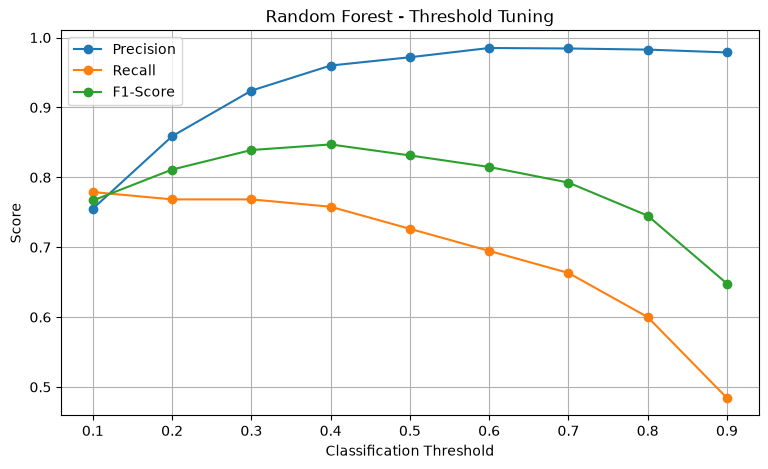

In [35]:
plt.figure(figsize=(9, 5))

plt.plot(threshold_results['Threshold'],
         threshold_results['Precision'],
         marker='o', label='Precision')

plt.plot(threshold_results['Threshold'],
         threshold_results['Recall'],
         marker='o', label='Recall')

plt.plot(threshold_results['Threshold'],
         threshold_results['F1-Score'],
         marker='o', label='F1-Score')

plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Random Forest - Threshold Tuning')
plt.legend()
plt.grid(True)

plt.show()

Observations – Threshold Tuning

* Evaluated nine classification thresholds (0.1–0.9).
* Threshold 0.4 achieved the highest F1-score of 0.85.
* Recall improved from 73% to 76%, with 96% precision.

Conclusion: Threshold tuning improved fraud detection performance while maintaining high precision.

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.96      0.76      0.85        95

    accuracy                           1.00     56746
   macro avg       0.98      0.88      0.92     56746
weighted avg       1.00      1.00      1.00     56746



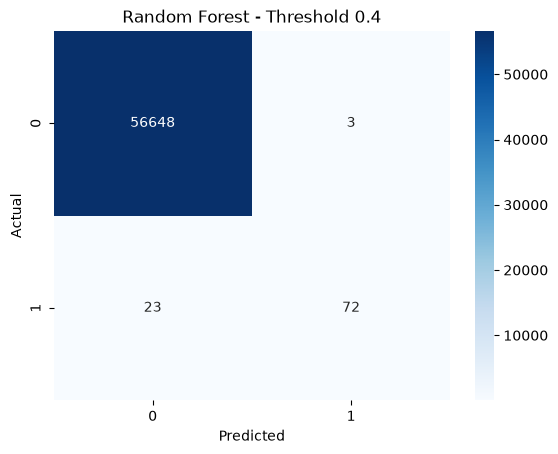

In [36]:
y_pred_04 = (y_prob_rf >= 0.4).astype(int)

print(classification_report(y_test, y_pred_04))

cm = confusion_matrix(y_test, y_pred_04)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title('Random Forest - Threshold 0.4')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

6: Proper Validation-Based Threshold Selection.

In [37]:
from sklearn.model_selection import train_test_split

X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training:", X_train_new.shape)
print("Validation:", X_val.shape)

Training: (181584, 30)
Validation: (45396, 30)


In [38]:
best_rf = RandomForestClassifier(
    **random_search.best_params_,
    random_state=42,
    n_jobs=-1
)

best_rf.fit(X_train_new, y_train_new)

y_val_prob = best_rf.predict_proba(X_val)[:, 1]

In [39]:
thresholds = np.arange(0.1, 0.91, 0.01)

best_threshold = 0
best_f1 = 0

for threshold in thresholds:

    y_val_pred = (y_val_prob >= threshold).astype(int)

    score = f1_score(y_val, y_val_pred)

    if score > best_f1:
        best_f1 = score
        best_threshold = threshold

print("Best Threshold:", best_threshold)
print("Validation F1-Score:", best_f1)

Best Threshold: 0.34999999999999987
Validation F1-Score: 0.896551724137931


In [40]:
best_rf.fit(X_train, y_train)

y_test_prob = best_rf.predict_proba(X_test)[:, 1]

y_test_pred = (y_test_prob >= best_threshold).astype(int)

print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.95      0.75      0.84        95

    accuracy                           1.00     56746
   macro avg       0.97      0.87      0.92     56746
weighted avg       1.00      1.00      1.00     56746



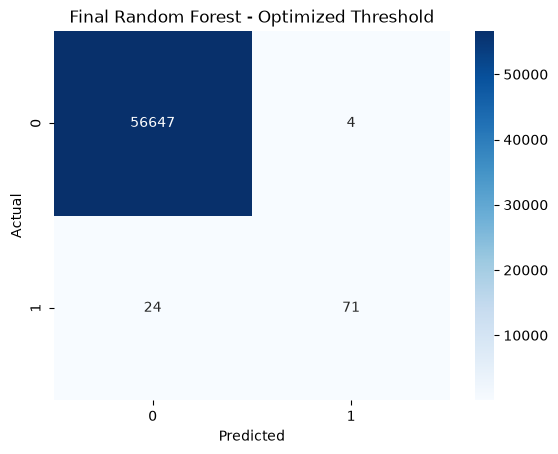

In [41]:
cm = confusion_matrix(y_test, y_test_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title('Final Random Forest - Optimized Threshold')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Conclusion: Validation-based threshold selection produced a reliable Random Forest model with a good balance between precision and recall.

In [42]:
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': best_rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance', ascending=False
)

feature_importance.head(15)

,Feature,Importance
17,V17,0.159175
14,V14,0.135473
12,V12,0.134319
16,V16,0.088949
10,V10,0.071153
11,V11,0.068800
9,V9,0.053081
4,V4,0.032202
18,V18,0.032079
7,V7,0.024485


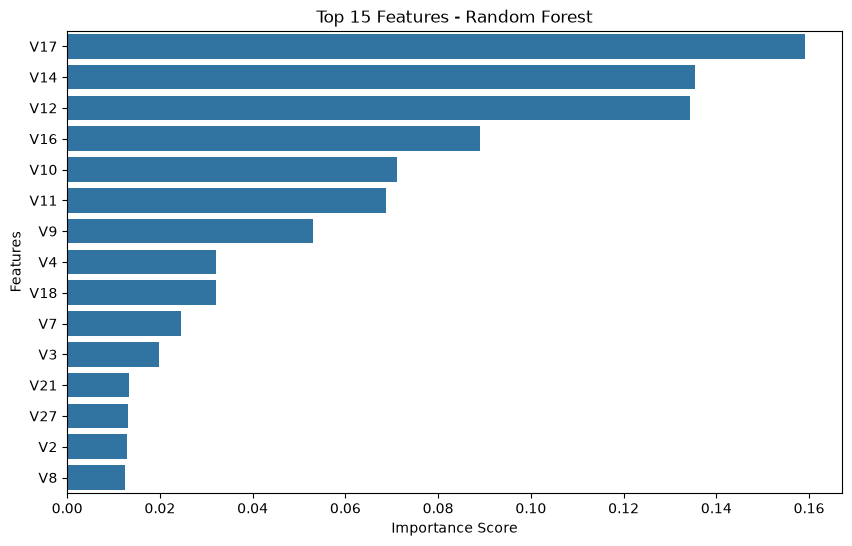

In [43]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x='Importance',
    y='Feature',
    data=feature_importance.head(15)
)

plt.title('Top 15 Features - Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Features')

plt.show()

Observations – Feature Importance

* V17, V14 and V12 are the three most influential features.
* Anonymised transaction features contribute more than Amount and Time.
* Random Forest identifies patterns across multiple transaction features to detect fraud.

8. FINAL MODEL COMPARISON

In [44]:
models = {
    'Logistic Regression': y_pred_lr,
    'Decision Tree': y_pred_dt,
    'Random Forest': y_pred_rf,
    'XGBoost': y_pred_xgb,
    'Tuned Random Forest': y_test_pred
}

comparison = []

for name, predictions in models.items():

    comparison.append({
        'Model': name,
        'Precision': precision_score(y_test, predictions),
        'Recall': recall_score(y_test, predictions),
        'F1-Score': f1_score(y_test, predictions)
    })

comparison_df = pd.DataFrame(comparison)

comparison_df = comparison_df.sort_values(
    by='F1-Score', ascending=False
)

comparison_df

,Model,Precision,Recall,F1-Score
4,Tuned Random Forest,0.946667,0.747368,0.835294
2,Random Forest,0.971831,0.726316,0.831325
3,XGBoost,0.957746,0.715789,0.819277
1,Decision Tree,0.720430,0.705263,0.712766
0,Logistic Regression,0.846154,0.578947,0.687500


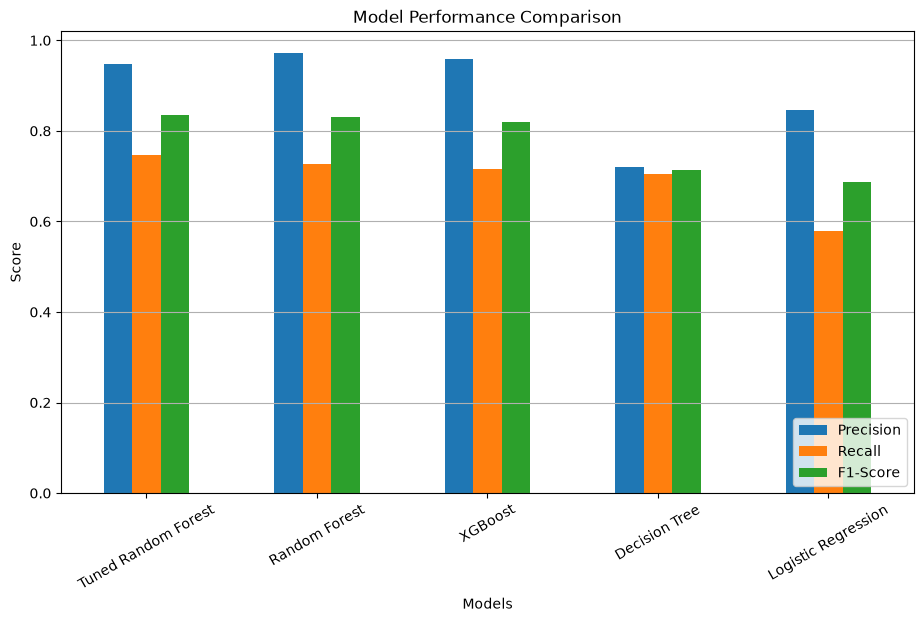

In [45]:
comparison_df.set_index('Model').plot(
    kind='bar',
    figsize=(11, 6)
)

plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.xlabel('Models')
plt.xticks(rotation=30)
plt.legend(loc='lower right')
plt.grid(axis='y')

plt.show()

Conclusion: Tuned Random Forest is our final model, achieving the best overall F1-score while maintaining high precision and recall.

In [46]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

model_bundle = {
    'model': best_rf,
    'threshold': best_threshold
}

joblib.dump(model_bundle, "../models/fraud_detection_rf.joblib")

print("Model saved successfully!")

Model saved successfully!


In [47]:
import joblib

saved_bundle = joblib.load("../models/fraud_detection_rf.joblib")
print("Model:", saved_bundle['model'])
print("Threshold:", saved_bundle['threshold'])

Model: RandomForestClassifier(max_depth=10, max_features='log2', min_samples_split=5,
                       n_estimators=113, n_jobs=-1, random_state=42)
Threshold: 0.34999999999999987
